# Hierarchical (Agglomerative) Clustering

Build a tree of clusters from the bottom up: every point starts alone, then the **two closest clusters are merged**, over and over, until one cluster holds everything. The whole merge history is a *dendrogram*; cutting it at a height (or at `n_clusters` groups) gives a flat clustering. No need to choose `k` up front — and you can look at the tree to pick it.

"Closest" for two clusters depends on the **linkage**:

| Linkage | Distance between clusters | Tends to find |
|---|---|---|
| `single` | nearest pair of points | elongated / chained shapes (but sensitive to noise bridges) |
| `complete` | farthest pair of points | compact clusters |
| `average` | mean of all pairwise distances | a compromise |
| `ward` | smallest increase in within-cluster variance | round clusters of similar size (the usual default) |

After a merge, distances to the new cluster are computed from the old distances alone (Lance–Williams update), e.g. single: `min(d_ik, d_jk)`, average: `(n_i·d_ik + n_j·d_jk) / (n_i + n_j)`.

`linkage_matrix_` is in scipy's format — rows `[cluster_a, cluster_b, distance, size]`, merged clusters numbered `n, n+1, ...` — so `scipy.cluster.hierarchy.dendrogram` can plot it directly. The test and demo check the merge heights against `scipy.cluster.hierarchy.linkage`.

Cost is `O(n³)` time and `O(n²)` memory.

## Usage

```python
# (the class is defined in the Implementation section below)

model = AgglomerativeClustering(n_clusters=3, linkage="ward").fit(X)
model.labels_
model.linkage_matrix_    # the full tree
```

This notebook is self-contained: the explanation, the implementation, the visuals, the scikit-learn check and the tests are all here.

## Setup

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.25, "axes.spines.top": False, "axes.spines.right": False})

## Implementation

The whole algorithm, as a plain Python class (numpy only).

In [2]:
import numpy as np


class AgglomerativeClustering:
    """Bottom-up hierarchical clustering. Start with every point as its own cluster and repeatedly
    merge the two CLOSEST clusters until one remains. The full merge history is kept in
    linkage_matrix_ (scipy's format), and cutting it at n_clusters gives labels_.

    How "closest" is defined for two clusters is the linkage:
        single    nearest pair of points        (can chain; finds elongated shapes)
        complete  farthest pair of points       (compact clusters)
        average   mean over all pairs           (a compromise)
        ward      smallest increase in total within-cluster variance (round, equal-sized clusters)

    Distances to a merged cluster are updated directly from the old ones (Lance-Williams
    formulas), so points are never revisited.

    ponytail: O(n^3) time, O(n^2) memory (full distance matrix, linear scan for the minimum).
    Fine for a few hundred points; use a nearest-neighbour-chain algorithm for more."""

    def __init__(self, n_clusters=2, linkage="ward"):
        self.n_clusters = n_clusters
        self.linkage = linkage

    def fit(self, X):
        X = np.asarray(X, dtype=float)
        n = len(X)
        D = np.sqrt(((X[:, None] - X[None]) ** 2).sum(axis=2))
        if self.linkage == "ward":
            D = D**2  # ward's update is linear in SQUARED distances
        np.fill_diagonal(D, np.inf)

        ids = list(range(n))  # current cluster id sitting in each row (leaves are 0..n-1)
        size = np.ones(n)
        Z = []
        for step in range(n - 1):
            i, j = np.unravel_index(np.argmin(D), D.shape)
            i, j = min(i, j), max(i, j)
            d_ij = D[i, j]
            Z.append([min(ids[i], ids[j]), max(ids[i], ids[j]),
                      np.sqrt(d_ij) if self.linkage == "ward" else d_ij, size[i] + size[j]])

            d_i, d_j, n_i, n_j, n_k = D[i].copy(), D[j].copy(), size[i], size[j], size
            if self.linkage == "single":
                new = np.minimum(d_i, d_j)
            elif self.linkage == "complete":
                new = np.maximum(d_i, d_j)
            elif self.linkage == "average":
                new = (n_i * d_i + n_j * d_j) / (n_i + n_j)
            elif self.linkage == "ward":
                new = ((n_i + n_k) * d_i + (n_j + n_k) * d_j - n_k * d_ij) / (n_i + n_j + n_k)
            else:
                raise ValueError(f"unknown linkage: {self.linkage}")

            new[i] = new[j] = np.inf
            D[i, :] = new  # row/column i now stands for the merged cluster...
            D[:, i] = new
            D[j, :] = np.inf  # ...and j is retired
            D[:, j] = np.inf
            size[i] = n_i + n_j
            ids[i] = n + step

        self.linkage_matrix_ = np.array(Z)
        self.labels_ = self._cut(n, self.n_clusters)
        return self

    def fit_predict(self, X):
        return self.fit(X).labels_

    def _cut(self, n, n_clusters):
        """Replay the first n - n_clusters merges and read off the surviving clusters."""
        members = {i: [i] for i in range(n)}
        for step, (a, b, _, _) in enumerate(self.linkage_matrix_[: n - n_clusters]):
            members[n + step] = members.pop(int(a)) + members.pop(int(b))
        labels = np.empty(n, dtype=int)
        for label, leaves in enumerate(sorted(members.values(), key=min)):
            labels[leaves] = label
        return labels

## See it work

### 1. The dendrogram

Agglomerative clustering starts with every point as its own cluster and repeatedly **merges the two closest clusters**. The full merge history is a tree, the dendrogram; the height of a merge is the distance at which it happened. Cutting the tree at any height gives a flat clustering. `linkage_matrix_` is in scipy's format, so scipy can draw it.

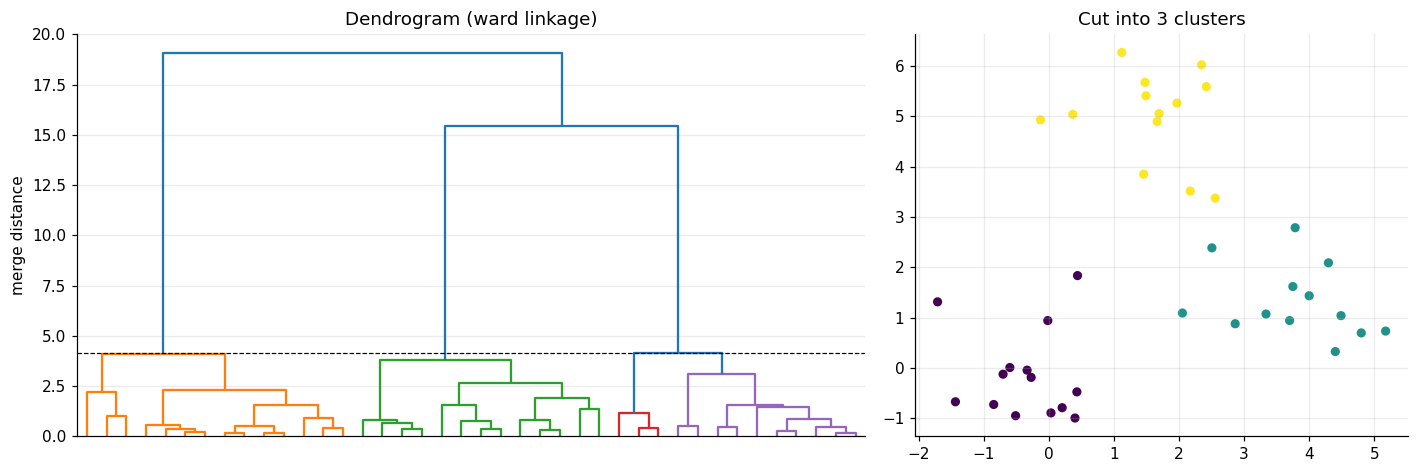

In [3]:
from scipy.cluster.hierarchy import dendrogram
from sklearn.datasets import make_blobs

X, _ = make_blobs(n_samples=40, centers=[[0, 0], [4, 1], [2, 5]], cluster_std=0.8, random_state=2)
m = AgglomerativeClustering(n_clusters=3, linkage="ward").fit(X)
fig, (a, b) = plt.subplots(1, 2, figsize=(13, 4.4), gridspec_kw={"width_ratios": [1.6, 1]})
dendrogram(m.linkage_matrix_, ax=a, color_threshold=m.linkage_matrix_[-3, 2] * 0.999, no_labels=True); a.set(title="Dendrogram (ward linkage)", ylabel="merge distance")
a.axhline(m.linkage_matrix_[-3, 2] * 0.999, color="k", ls="--", lw=0.8)
b.scatter(*X.T, c=m.labels_, cmap="viridis", s=25); b.set_title("Cut into 3 clusters"); plt.tight_layout(); plt.show()

### 2. Linkage = how to measure the distance between clusters

- **single**: closest pair of points. Follows chains and curves, but suffers "chaining".
- **complete**: farthest pair. Compact clusters of similar diameter.
- **average**: mean of all pairwise distances.
- **ward**: merge the pair that increases within-cluster variance the least. Tends to give equal-sized round clusters (like K-Means).

On two interleaved moons only single linkage recovers the true shapes. On the three blobs below (two of them overlap), ward and complete split the data into sensible groups, while single and average just peel off a few outlying points.

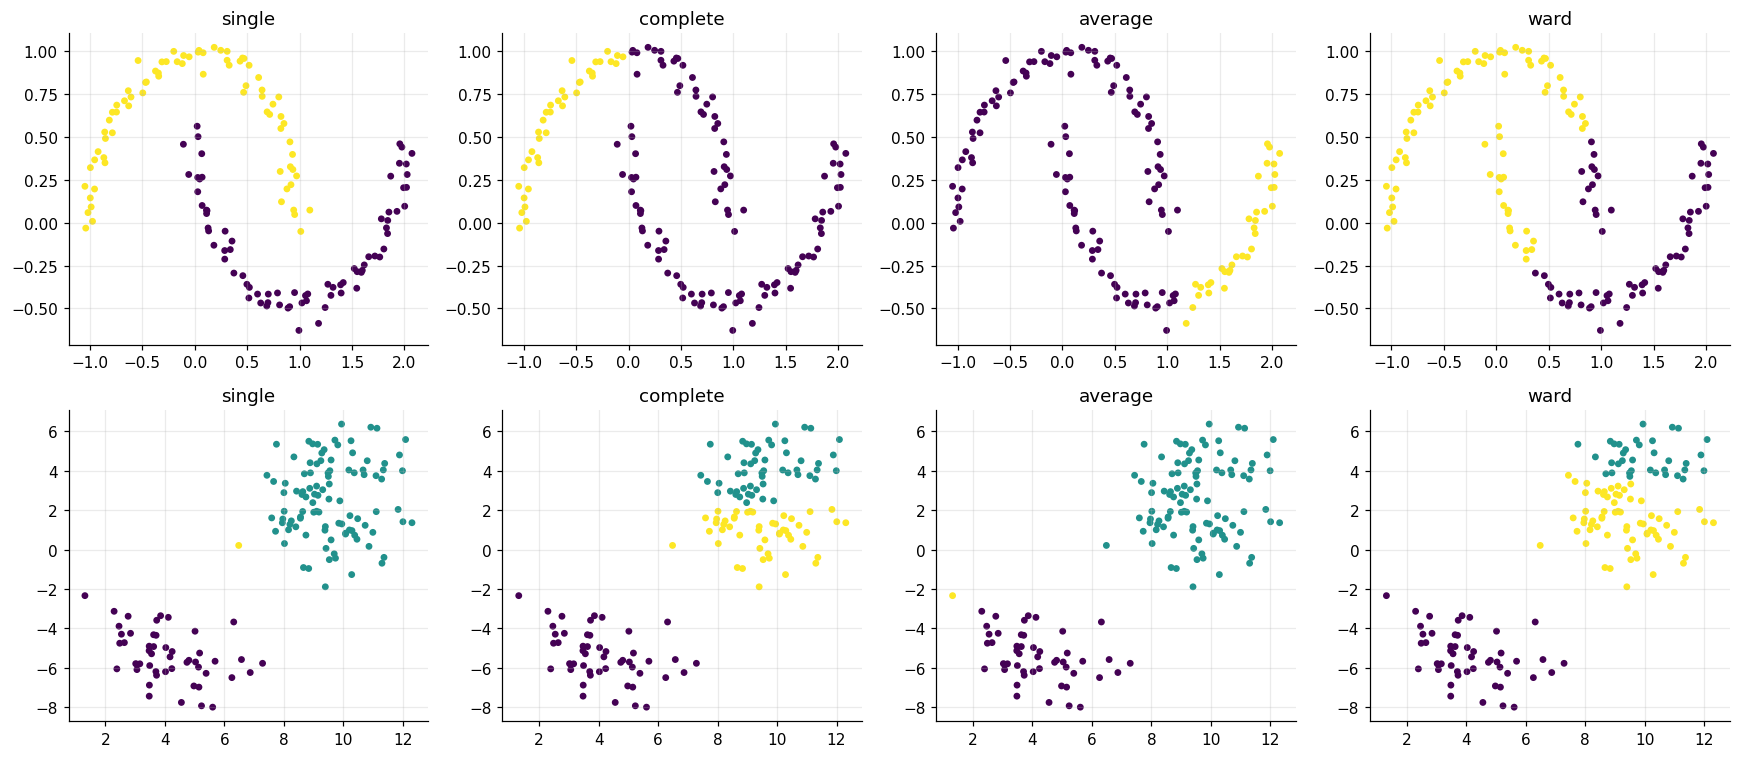

In [4]:
from sklearn.datasets import make_moons

Xm, _ = make_moons(n_samples=150, noise=0.05, random_state=0)
Xb, _ = make_blobs(n_samples=150, centers=3, cluster_std=1.2, random_state=4)
fig, axes = plt.subplots(2, 4, figsize=(16, 7))
for i, (data, k) in enumerate([(Xm, 2), (Xb, 3)]):
    for j, link in enumerate(["single", "complete", "average", "ward"]):
        lab = AgglomerativeClustering(n_clusters=k, linkage=link).fit(data).labels_
        axes[i, j].scatter(*data.T, c=lab, cmap="viridis", s=12); axes[i, j].set_title(link)
plt.tight_layout(); plt.show()

### 3. Choosing the number of clusters from the merge heights

A big jump in merge distance means the next merge joins two clusters that are far apart, a natural place to stop. The last few merge heights for the blobs above:

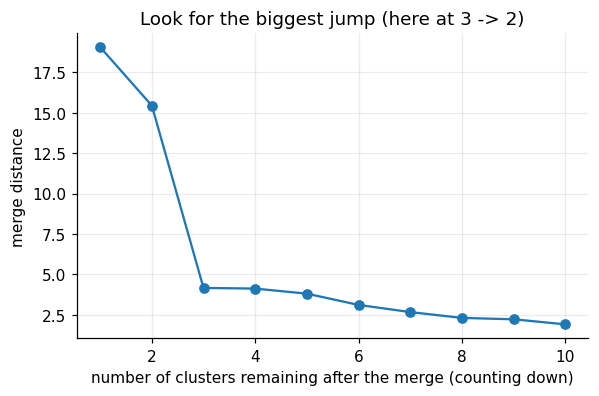

In [5]:
heights = m.linkage_matrix_[:, 2]
plt.figure(figsize=(6, 3.6)); plt.plot(range(1, 11), heights[::-1][:10], "o-")
plt.xlabel("number of clusters remaining after the merge (counting down)"); plt.ylabel("merge distance"); plt.title("Look for the biggest jump (here at 3 -> 2)"); plt.show()

## Check against a reference implementation

Same data, same settings as scikit-learn (or scipy / the real library). The assertions fail if the two disagree.

In [6]:
import numpy as np
from scipy.cluster.hierarchy import linkage
from sklearn.cluster import AgglomerativeClustering as SklearnAgglomerative
from sklearn.datasets import make_blobs, make_moons
from sklearn.metrics import adjusted_rand_score

X, truth = make_blobs(n_samples=200, centers=3, cluster_std=0.9, random_state=7)
print("blobs: merge heights vs scipy, labels vs sklearn")
for method in ("single", "complete", "average", "ward"):
    ours = AgglomerativeClustering(n_clusters=3, linkage=method).fit(X)
    heights_match = np.allclose(np.sort(ours.linkage_matrix_[:, 2]), np.sort(linkage(X, method)[:, 2]))
    ari = adjusted_rand_score(ours.labels_, SklearnAgglomerative(n_clusters=3, linkage=method).fit_predict(X))
    print("  %-9s heights match scipy: %s   label agreement with sklearn (ARI): %.4f" % (method, heights_match, ari))
    assert heights_match and ari > 0.99

# the linkage choice changes WHAT is found: on two moons only single linkage follows the curves
Xm, truth_m = make_moons(n_samples=200, noise=0.05, random_state=0)
print("moons, agreement with the true shapes (ARI):")
for method in ("single", "ward"):
    labels = AgglomerativeClustering(n_clusters=2, linkage=method).fit_predict(Xm)
    print("  %-9s %.4f" % (method, adjusted_rand_score(truth_m, labels)))
assert adjusted_rand_score(truth_m, AgglomerativeClustering(2, "single").fit_predict(Xm)) > 0.95
assert adjusted_rand_score(truth_m, AgglomerativeClustering(2, "ward").fit_predict(Xm)) < 0.6

blobs: merge heights vs scipy, labels vs sklearn
  single    heights match scipy: True   label agreement with sklearn (ARI): 1.0000
  complete  heights match scipy: True   label agreement with sklearn (ARI): 1.0000
  average   heights match scipy: True   label agreement with sklearn (ARI): 1.0000
  ward      heights match scipy: True   label agreement with sklearn (ARI): 1.0000
moons, agreement with the true shapes (ARI):
  single    1.0000
  ward      0.4331


## Tests

Plain `assert` tests that check the invariants of the algorithm.

In [7]:
import numpy as np


def test_merge_heights_match_scipy_for_every_linkage():
    from scipy.cluster.hierarchy import linkage

    rng = np.random.default_rng(0)
    X = rng.normal(size=(60, 3))
    for method in ("single", "complete", "average", "ward"):
        ours = AgglomerativeClustering(n_clusters=2, linkage=method).fit(X).linkage_matrix_
        theirs = linkage(X, method=method)
        assert np.allclose(np.sort(ours[:, 2]), np.sort(theirs[:, 2])), method
        assert ours[-1, 3] == 60  # the last merge contains every point


def test_merge_heights_never_decrease_for_monotone_linkages():
    rng = np.random.default_rng(1)
    X = rng.normal(size=(40, 2))
    for method in ("single", "complete", "average", "ward"):
        heights = AgglomerativeClustering(linkage=method).fit(X).linkage_matrix_[:, 2]
        assert (np.diff(heights) >= -1e-9).all(), method


def test_cutting_the_tree_recovers_separated_blobs():
    rng = np.random.default_rng(2)
    X = np.vstack([rng.normal(c, 0.4, (30, 2)) for c in ([0, 0], [8, 0], [0, 8])])
    for method in ("single", "complete", "average", "ward"):
        labels = AgglomerativeClustering(n_clusters=3, linkage=method).fit_predict(X)
        assert len(set(labels[:30])) == len(set(labels[30:60])) == len(set(labels[60:])) == 1, method
        assert len(set(labels)) == 3, method


def test_single_linkage_follows_a_chain_but_complete_does_not():
    # two long thin parallel lines: single linkage chains along each, complete linkage cuts across
    line = np.linspace(0, 10, 30)
    X = np.vstack([np.column_stack([line, np.zeros(30)]), np.column_stack([line, np.full(30, 3.0)])])
    single = AgglomerativeClustering(n_clusters=2, linkage="single").fit_predict(X)
    complete = AgglomerativeClustering(n_clusters=2, linkage="complete").fit_predict(X)
    assert len(set(single[:30])) == 1 and len(set(single[30:])) == 1 and single[0] != single[-1]
    assert len(set(complete[:30])) > 1 or len(set(complete[30:])) > 1

In [8]:
tests = [(name, fn) for name, fn in list(globals().items()) if name.startswith("test_") and callable(fn)]
for name, fn in tests:
    fn()
    print("PASS", name)
print(f"\nall {len(tests)} tests passed")

PASS test_merge_heights_match_scipy_for_every_linkage
PASS test_merge_heights_never_decrease_for_monotone_linkages
PASS test_cutting_the_tree_recovers_separated_blobs
PASS test_single_linkage_follows_a_chain_but_complete_does_not

all 4 tests passed


## Takeaways

- **Use it** when you want a hierarchy (taxonomies, gene expression), don't want to fix `k` up front, or have small-to-medium data (`O(n²)` memory, up to `O(n³)` time naively).
- **Choices that matter:** the linkage (above) and the distance metric; standardise features.
- **Cutting:** any number of clusters comes from one fit; draw the dendrogram to decide.
- **Pitfalls:** greedy and irreversible (an early bad merge is never undone); does not scale to huge `n`.
- **Interview line:** *"Bottom-up merging of the two closest clusters; linkage defines cluster distance; the dendrogram records all merges and can be cut at any level."*